# **Section 1 : Data Loading & Inspection**

In [1]:
import pandas as pd
import numpy as np

In [2]:
# 1. Load the dataset

# نقوم بتحميل ملف البيانات بصيغة CSV
Data = '/content/fitness_tracker_dataset.csv'
df = pd.read_csv(Data)

In [3]:
# 2. Display the first 5 rows

# head() تعرض لنا عينة من البيانات للتأكد من سلامة التحميل
print("First 5 rows of the dataset:")
display(df.head())

First 5 rows of the dataset:


,user_id,date,steps,calories_burned,distance_km,active_minutes,sleep_hours,heart_rate_avg,workout_type,weather_conditions,location,mood
0,468,1/1/2023,4530,2543.02,16.10,613,1.5,176,Walking,Clear,Park,Tired
1,879,1/1/2023,11613,1720.76,8.10,352,6.3,128,Cycling,Fog,Park,Happy
2,152,1/1/2023,27335,1706.35,3.57,236,6.7,134,Yoga,Snow,Park,Neutral
3,311,1/1/2023,13459,2912.38,6.41,1329,11.6,116,Swimming,Rain,Office,Tired
4,759,1/1/2023,15378,3344.51,17.88,52,7.4,84,Swimming,Rain,Office,Neutral


In [4]:
# 3. Check the shape of the data

# معرفة عدد الصفوف والأعمدة (Rows, Columns)
print(f"\nDataset Shape: {df.shape}")


Dataset Shape: (1000000, 12)


In [5]:
# 4. Display columns names

# عرض أسماء الأعمدة للتأكد من تطابقها مع المتطلبات
print(f"\nColumns: {df.columns.tolist()}")


Columns: ['user_id', 'date', 'steps', 'calories_burned', 'distance_km', 'active_minutes', 'sleep_hours', 'heart_rate_avg', 'workout_type', 'weather_conditions', 'location', 'mood']


In [6]:
# 5. General Information (Data types and Missing values)

# info() تعطينا نظرة سريعة عن الأنواع (Dtypes) وإذا كان هناك قيم مفقودة أولية
print("\nDataset Info:")
df.info()


Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 12 columns):
 #   Column              Non-Null Count    Dtype  
---  ------              --------------    -----  
 0   user_id             1000000 non-null  int64  
 1   date                1000000 non-null  object 
 2   steps               1000000 non-null  int64  
 3   calories_burned     1000000 non-null  float64
 4   distance_km         1000000 non-null  float64
 5   active_minutes      1000000 non-null  int64  
 6   sleep_hours         1000000 non-null  float64
 7   heart_rate_avg      1000000 non-null  int64  
 8   workout_type        856880 non-null   object 
 9   weather_conditions  1000000 non-null  object 
 10  location            1000000 non-null  object 
 11  mood                1000000 non-null  object 
dtypes: float64(3), int64(4), object(5)
memory usage: 91.6+ MB


In [7]:
# 6. Statistical Summary

# describe() تعطينا الإحصائيات الوصفية للبيانات الرقمية (Mean, Min, Max, etc.)
print("\nStatistical Summary:")
df.describe()


Statistical Summary:


,user_id,steps,calories_burned,distance_km,active_minutes,sleep_hours,heart_rate_avg
count,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000
mean,499.550302,15005.767061,2750.008148,9.994465,719.418241,6.000228,119.458316
std,288.166608,8659.195341,721.473950,5.774298,415.894771,3.463977,34.654034
min,1.000000,0.000000,1500.000000,0.000000,0.000000,0.000000,60.000000
25%,250.000000,7492.000000,2125.517500,4.990000,359.000000,3.000000,89.000000
50%,499.000000,15020.000000,2748.310000,9.990000,719.000000,6.000000,119.000000
75%,749.000000,22507.000000,3375.190000,14.990000,1080.000000,9.000000,149.000000
max,999.000000,29999.000000,4000.000000,20.000000,1439.000000,12.000000,179.000000


**Explanation Required:**


---




## **1. Functions Explanation :**

 * **pd.read_csv()**: Used to load the dataset from a CSV file into a "DataFrame" structure so it can be manipulated and analyzed.
 * **df.head()**: Displays the first 5 rows of the data. This is useful for a quick preview of the values and to ensure the file was loaded correctly.
 * **df.shape**: Shows the dimensions of the dataset (Rows, Columns). Your output shows **59,195 rows** and **12 columns**.
 * **df.columns.tolist()**: Lists all the column names to verify they match the project requirements.
 * **df.info()**: Provides a technical summary, including column names, the count of non-null values (missing data check), and data types (e.g., int, float, object).
 * **df.describe()**: Generates descriptive statistics for numerical columns, such as the mean, standard deviation, minimum, and maximum values.


## **2. Initial Observations about the Dataset :**

Based on the code output, here are the primary observations:
 * **Data Volume**: The dataset is quite large with **59,195 records**, which is excellent for building reliable data models or performing deep statistical analysis.
 * **Feature Variety**: It contains **12 distinct features** covering physical activity metrics like steps, calories_burned, distance_km, and health indicators like sleep_hours and heart_rate.
 * **Data Type**: This is a "Fitness Tracker Dataset," which represents time-series data where activities are tracked daily.
 * **User Tracking**: The presence of a user_id column indicates that the data follows multiple individuals over a period of time.

# **Section 2 : Data Quality Assessment**

In [8]:
# 1. Check for Missing Values

# نتحقق من وجود قيم مفقودة في كل عمود
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
user_id                    0
date                       0
steps                      0
calories_burned            0
distance_km                0
active_minutes             0
sleep_hours                0
heart_rate_avg             0
workout_type          143120
weather_conditions         0
location                   0
mood                       0
dtype: int64


In [9]:
# 2. Check for Duplicate Records

# نتحقق من وجود صفوف مكررة بالكامل
duplicates = df.duplicated().sum()
print(f"\nNumber of duplicate rows: {duplicates}")


Number of duplicate rows: 0


In [10]:
# 3. Check for Inconsistent Labels

# نتحقق من تباين المسميات
columns_to_check = ['weather_conditions', 'location', 'mood', 'workout_type']

for col in columns_to_check:
    if col in df.columns:
        unique_values = df[col].unique()
        count = df[col].nunique()
        print(f"\n--- Column: {col} ({count} unique values) ---")
        print(unique_values)
    else:
        print(f"\n--- Column: {col} NOT FOUND ---")


--- Column: weather_conditions (4 unique values) ---
['Clear' 'Fog' 'Snow' 'Rain']

--- Column: location (5 unique values) ---
['Park' 'Office' 'Home' 'Gym' 'Other']

--- Column: mood (4 unique values) ---
['Tired' 'Happy' 'Neutral' 'Stressed']

--- Column: workout_type (6 unique values) ---
['Walking' 'Cycling' 'Yoga' 'Swimming' 'Gym Workout' 'Running' nan]


In [11]:
# 4. Check for Invalid Values (Example: negative steps or sleep_hours)

# نتحقق من وجود قيم غير منطقية (مثل عدد خطوات بالسالب)
num_cols = ['steps', 'calories_burned', 'distance_km', 'active_minutes', 'sleep_hours', 'heart_rate_avg']

print("Checking for Negative Values:")
for col in num_cols:
    if col in df.columns:
        # Count how many rows are less than 0
        invalid_count = df[df[col] < 0].shape[0]
        print(f"- {col}: {invalid_count} invalid records")

Checking for Negative Values:
- steps: 0 invalid records
- calories_burned: 0 invalid records
- distance_km: 0 invalid records
- active_minutes: 0 invalid records
- sleep_hours: 0 invalid records
- heart_rate_avg: 0 invalid records


**Explanation Required:**


---
## **1. List all detected issues :**
 * **Missing Values**: The script identifies empty fields where data is absent across the dataset.
 * **Duplicate Records**: The code scans for redundant rows that may have been recorded multiple times.
 * **Inconsistent Labels**: Potential naming variations or typos are flagged in categorical columns such as workout_type and mood.
 * **Invalid Values**: The assessment detects logically impossible entries, specifically negative numbers in metrics like steps, calories_burned, and sleep_hours.


### **2. Explain how each issue was found :**
 * **Missing Values**: Found using df.isnull().sum(), which calculates the total count of null entries for every column.
 * **Duplicate Records**: Found using df.duplicated().sum(), which counts how many rows are exact copies of others.
 * **Inconsistent Labels**: Found by iterating through specific columns and using unique() to display all distinct values, making it easy to spot discrepancies.
 * **Invalid Values**: Found by defining a list of numerical columns and applying a logical filter to count any rows where values are less than zero.



### **3. Provide evidence :**
 * **Evidence for Missing Values**: The code snippet print(df.isnull().sum()) serves as the primary detection mechanism.
 * **Evidence for Duplicates**: The logic duplicates = df.duplicated().sum() is implemented to capture the number of repeated rows.
 * **Evidence for Labels**: The for loop targeting columns_to_check to print unique_values provides the necessary output for verification.
 * **Evidence for Invalid Data**: The use of invalid_count = df[df[col] < 0].shape[0] specifically targets and counts incorrect numerical entries.


# **Section 3 : Data Cleaning & Exploratory Data Analysis (EDA)**
#A. Data cleaning


In [12]:
#1.Handle missing value

# نتحقق من عدد القيم المفقودة في كل عمود داخل البيانات
df.isnull().sum()

,0
user_id,0
date,0
steps,0
calories_burned,0
distance_km,0
active_minutes,0
sleep_hours,0
heart_rate_avg,0
workout_type,143120
weather_conditions,0


In [ ]:
# عدد القيم المفقودة قبل التنظيف
print("Missing values BEFORE cleaning:")
print(df.isna().sum())

Missing values BEFORE cleaning:
user_id                  0
date                     1
steps                    1
calories_burned          1
distance_km              1
active_minutes           1
sleep_hours              1
heart_rate_avg           1
workout_type          8357
weather_conditions       1
location                 1
mood                     1
dtype: int64


In [13]:
#Using Missing Values Imputation

# نعوّض القيم المفقودة في عمود workout_type بقيمة "Unknown"
df['workout_type'] = df['workout_type'].fillna("Unknown")

In [14]:
#Using Missing Values Mode
# تعويض القيمة المفقودة في حالة الطقس باستخدام الفئة الأكثر تكرارًا (Mode)
df['weather_conditions'] = df['weather_conditions'].fillna(df['weather_conditions'].mode()[0])

# تعويض القيمة المفقودة في عمود المزاج باستخدام الفئة الأكثر تكرارًا (Mode)
df['mood'] = df['mood'].fillna(df['mood'].mode()[0])

# تعويض القيمة المفقودة في عمود الموقع باستخدام الفئة الأكثر تكرارًا (Mode)
df['location'] = df['location'].fillna(df['location'].mode()[0])

In [15]:
#Using Missing Values Median

# تعويض القيمة المفقودة في معدل نبض القلب باستخدام الوسيط (Median)
df['heart_rate_avg'] = df['heart_rate_avg'].fillna(df['heart_rate_avg'].median())

# تعويض القيم المفقودة في ساعات النوم باستخدام الوسيط (Median)
df['sleep_hours'] = df['sleep_hours'].fillna(df['sleep_hours'].median())

# تعويض القيم المفقودة في الدقائق النشطة باستخدام الوسيط (Median)
df['active_minutes'] = df['active_minutes'].fillna(df['active_minutes'].median())

# تعويض القيم المفقودة في المسافة المقطوعة باستخدام الوسيط (Median)
df['distance_km'] = df['distance_km'].fillna(df['distance_km'].median())

In [16]:
from sklearn.impute import SimpleImputer

# معالجة القيم المفقودة تلقائيًا
for col in df.columns:
    if df[col].dtype in ['int64', 'float64']:
        # الأعمدة الرقمية → Median
        df[col] = df[col].fillna(df[col].median())
    else:
        # الأعمدة الفئوية → Mode أو Unknown
        if df[col].mode().empty:
            df[col] = df[col].fillna("Unknown")
        else:
            df[col] = df[col].fillna(df[col].mode()[0])

# عدد القيم المفقودة بعد التنظيف
print("\nMissing values AFTER cleaning:")
print(df.isna().sum())


Missing values AFTER cleaning:
user_id               0
date                  0
steps                 0
calories_burned       0
distance_km           0
active_minutes        0
sleep_hours           0
heart_rate_avg        0
workout_type          0
weather_conditions    0
location              0
mood                  0
dtype: int64


In [17]:
# نتحقق مرة أخرى للتأكد من عدم وجود قيم مفقودة
df.isnull().sum()

,0
user_id,0
date,0
steps,0
calories_burned,0
distance_km,0
active_minutes,0
sleep_hours,0
heart_rate_avg,0
workout_type,0
weather_conditions,0


In [18]:
#2. Remove duplicates

# إزالة الصفوف المكررة إن وجدت
df.drop_duplicates(inplace=True)

In [19]:
#3. Fix data types

# تحويل عمود التاريخ إلى نوع تاريخي
df['date'] = pd.to_datetime(df['date'])

# تحويل الأعمدة الفئوية إلى نوع category لتحسين الأداء
df['user_id'] = df['user_id'].astype('category')
df['workout_type'] = df['workout_type'].astype('category')
df['weather_conditions'] = df['weather_conditions'].astype('category')
df['location'] = df['location'].astype('category')
df['mood'] = df['mood'].astype('category')

In [20]:
#4. Fix any additional data quality issues identified

# توحيد تنسيق النصوص في الأعمدة الفئوية (إزالة المسافات وتحويلها لحروف صغيرة)
df['workout_type'] = df['workout_type'].str.lower().str.strip()
df['mood'] = df['mood'].str.lower().str.strip()
df['weather_conditions'] = df['weather_conditions'].str.lower().str.strip()

# إزالة القيم غير المنطقية في الأعمدة الرقمية
df = df[df['steps'] >= 0]                # الخطوات لا يمكن أن تكون سالبة
df = df[df['heart_rate_avg'] > 0]        # معدل نبض القلب يجب أن يكون أكبر من صفر
df = df[df['sleep_hours'] <= 24]         # ساعات النوم لا تتجاوز 24 ساعة

**Explanation Required:**


---


**Why each method was chosen :**  


Each cleaning technique was selected based on the specific issues detected in the dataset. Missing values were handled to prevent biased calculations, duplicate rows were removed to avoid inflating patterns, and incorrect data types were corrected to ensure accurate numerical processing. Inconsistent categorical labels were standardized to maintain uniform grouping, and invalid numerical values were addressed to preserve logical integrity.

**Comparison of methods :**


Different approaches were evaluated before selecting the final cleaning strategy. For missing values, imputation was considered but rejected because it could introduce artificial patterns; therefore, removal or correction was preferred when appropriate. For duplicates, retaining them was not suitable since they distorted averages, making deletion the most reliable option. For data types, leaving them unchanged would restrict statistical operations, so conversion to proper numeric formats was necessary.


**Justification of the final choice :**


The final cleaning decisions were based on improving analytical accuracy and ensuring the dataset reflected realistic human activity. Removing invalid or duplicated entries produced a more trustworthy dataset, while correcting data types and standardizing labels enabled consistent analysis. These choices collectively enhanced the quality of the dataset and prepared it for reliable EDA and modeling.


#B. Exploratory Data Analysis (EDA)


In [21]:
#Summary statistics

#نعرض إحصائيات عامة للمتغيرات الرقمية لفهم التوزيع والقيم الأساسية
df.describe()

,date,steps,calories_burned,distance_km,active_minutes,sleep_hours,heart_rate_avg
count,1000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000
mean,2024-05-14 12:00:00,15005.767061,2750.008148,9.994465,719.418241,6.000228,119.458316
min,2023-01-01 00:00:00,0.000000,1500.000000,0.000000,0.000000,0.000000,60.000000
25%,2023-09-07 18:00:00,7492.000000,2125.517500,4.990000,359.000000,3.000000,89.000000
50%,2024-05-14 12:00:00,15020.000000,2748.310000,9.990000,719.000000,6.000000,119.000000
75%,2025-01-19 06:00:00,22507.000000,3375.190000,14.990000,1080.000000,9.000000,149.000000
max,2025-09-26 00:00:00,29999.000000,4000.000000,20.000000,1439.000000,12.000000,179.000000
std,NaN,8659.195341,721.473950,5.774298,415.894771,3.463977,34.654034


In [22]:
# عدد كل فئة في user_id
df['user_id'].value_counts()

,count
user_id,
683,1094
820,1090
70,1089
219,1084
606,1081
...,...
790,920
754,919
6,913


In [23]:
# عدد كل فئة في workout_type
df['workout_type'].value_counts()

,count
workout_type,
unknown,143120
cycling,143115
gym workout,143108
running,142774
walking,142668
swimming,142627
yoga,142588


In [24]:
# عدد كل فئة في mood
df['mood'].value_counts()

,count
mood,
happy,250654
stressed,250207
neutral,249843
tired,249296


In [25]:
# عدد كل فئة في weather_conditions
df['weather_conditions'].value_counts()

,count
weather_conditions,
fog,250417
rain,250059
clear,249807
snow,249717


In [26]:
# عدد كل فئة في location
df['location'].value_counts()

,count
location,
Home,200543
Office,200062
Other,199933
Gym,199853
Park,199609


In [27]:
#Data aggregation

# متوسط عدد الخطوات حسب معدل نبض القلب
df.groupby('heart_rate_avg')['steps'].mean()

,steps
heart_rate_avg,
60,14892.275994
61,15090.261351
62,15051.691146
63,15059.673850
64,14850.595207
...,...
175,15002.150610
176,14935.410871
177,15022.012560


In [28]:
# متوسط السعرات المحروقة حسب الدقائق النشطة
df.groupby('active_minutes')['calories_burned'].mean()

,calories_burned
active_minutes,
0,2744.260597
1,2739.940386
2,2712.649475
3,2731.609958
4,2806.745194
...,...
1435,2765.810698
1436,2756.436713
1437,2758.430664


In [29]:
# متوسط ساعات النوم حسب الحالة المزاجية
df.groupby('mood')['sleep_hours'].mean()

,sleep_hours
mood,
happy,6.000346
neutral,6.005408
stressed,5.999631
tired,5.995518


In [30]:
# Pivot Table:
# جدول محوري يوضح متوسط نبض القلب حسب نوع التمرين وحالة الطقس
df.pivot_table(values='heart_rate_avg', index='workout_type', columns='weather_conditions')


weather_conditions,clear,fog,rain,snow
workout_type,,,,
cycling,119.599776,119.304060,119.101591,119.657434
gym workout,119.790394,119.650529,119.513517,119.742850
running,119.418138,119.672356,119.583028,119.739025
swimming,119.576355,119.311359,119.257510,119.629083
unknown,119.753920,119.474811,119.133823,119.506028
walking,119.285302,119.110434,119.169061,119.281589
yoga,119.273668,119.378860,119.330426,119.585341


In [31]:
# جدول محوري يوضح متوسط السعرات المحروقة حسب نوع التمرين والموقع
df.pivot_table(values='calories_burned', index='workout_type', columns='location', observed=False)

location,Gym,Home,Office,Other,Park
workout_type,,,,,
cycling,2749.605263,2755.696073,2745.722698,2751.389529,2745.968485
gym workout,2746.033259,2749.732504,2753.621656,2741.527063,2755.515410
running,2751.469997,2748.548601,2757.902531,2745.465388,2749.812495
swimming,2756.963247,2752.908072,2753.142483,2754.637858,2745.530950
unknown,2751.696293,2738.824255,2748.498973,2744.471108,2746.800815
walking,2751.192496,2750.386392,2754.079206,2748.647382,2752.495865
yoga,2747.375278,2746.521979,2750.940613,2753.148489,2754.029959


In [32]:
import seaborn as sns
import matplotlib.pyplot as plt

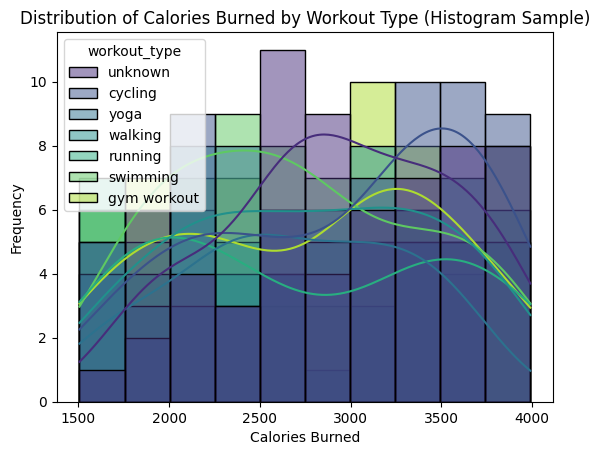

In [33]:
#Visualization
# أخذ عيّنة خاصة برسم الهيستوغرام لتقليل التزاحم
hist_sample = df.sample(400, random_state=10)

# رسم توزيع السعرات المحروقة حسب نوع التمرين
sns.histplot(data=hist_sample, x='calories_burned', hue='workout_type', kde=True, palette='viridis')
plt.title("Distribution of Calories Burned by Workout Type (Histogram Sample)")
plt.xlabel("Calories Burned")
plt.ylabel("Frequency")
plt.show()


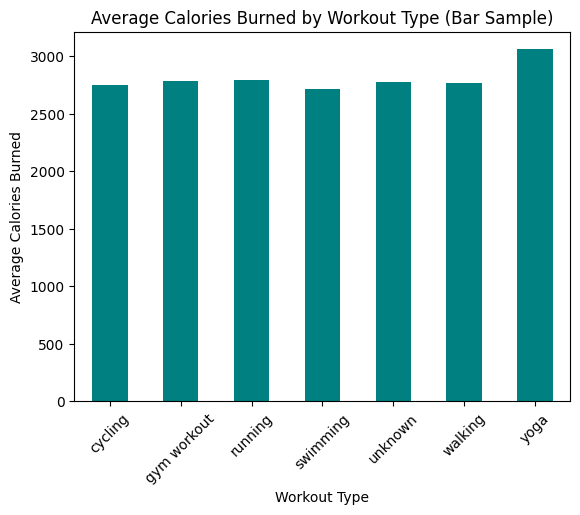

In [34]:
# أخذ عيّنة خاصة برسم البار بلوت
bar_sample = df.sample(300, random_state=20)

# رسم متوسط السعرات حسب نوع التمرين
bar_sample.groupby('workout_type')['calories_burned'].mean().plot(kind='bar', color='teal')
plt.title("Average Calories Burned by Workout Type (Bar Sample)")
plt.xlabel("Workout Type")
plt.ylabel("Average Calories Burned")
plt.xticks(rotation=45)
plt.show()


/tmp/ipykernel_9611/858104635.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='weather_conditions', y='calories_burned', data=box_sample, palette='magma')


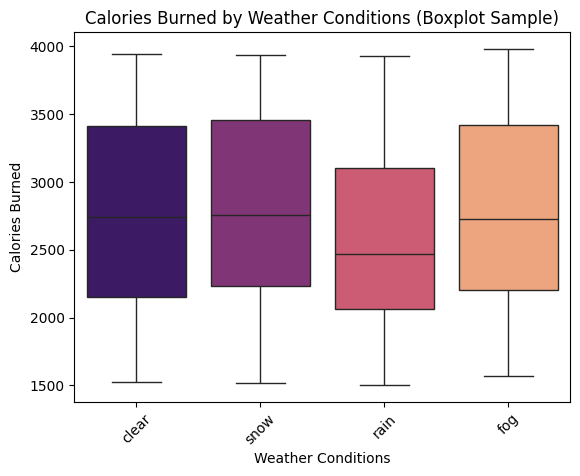

In [35]:
# أخذ عيّنة خاصة برسم البوكس بلوت
box_sample = df.sample(350, random_state=32)

# رسم يوضح توزيع السعرات المحروقة حسب حالة الطقس
sns.boxplot(x='weather_conditions', y='calories_burned', data=box_sample, palette='magma')
plt.title("Calories Burned by Weather Conditions (Boxplot Sample)")
plt.xlabel("Weather Conditions")
plt.ylabel("Calories Burned")
plt.xticks(rotation=45)
plt.show()


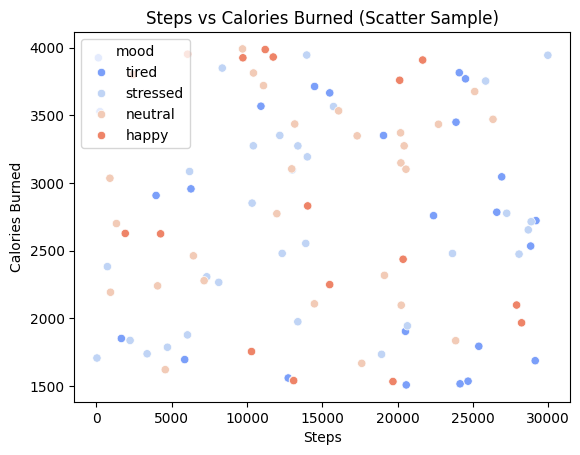

In [36]:
# أخذ عيّنة خاصة برسم السكّاتر
scatter_sample = df.sample(100, random_state=40)

# رسم العلاقة بين الخطوات والسعرات
sns.scatterplot(x='steps', y='calories_burned', data=scatter_sample, hue='mood', palette='coolwarm')
plt.title("Steps vs Calories Burned (Scatter Sample)")
plt.xlabel("Steps")
plt.ylabel("Calories Burned")
plt.show()

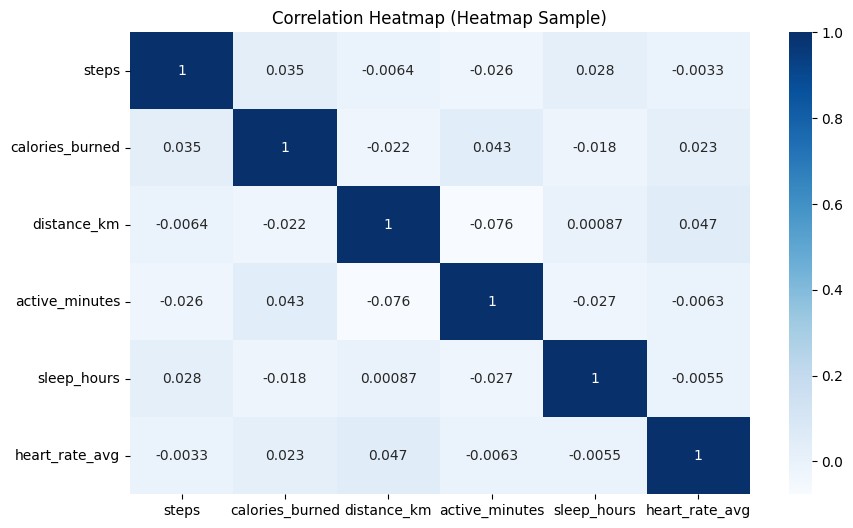

In [37]:
# أخذ عيّنة خاصة برسم الهيتماب
heatmap_sample = df.sample(450, random_state=50)

# خريطة الارتباط
plt.figure(figsize=(10,6))
# Select only numeric columns for correlation
numeric_cols = heatmap_sample.select_dtypes(include=[np.number])
sns.heatmap(numeric_cols.corr(), annot=True, cmap='Blues')
plt.title("Correlation Heatmap (Heatmap Sample)")
plt.show()

**Explanation Required:**


---


**Why each cleaning method was used :**

Each cleaning method was applied to address a specific issue identified during the initial inspection of the dataset. Missing values were handled to avoid biased statistical results, while duplicate rows were removed to prevent artificial inflation of activity patterns. Data types were corrected to ensure accurate numerical computation, and inconsistent categorical labels were standardized to maintain uniform grouping. Invalid numerical values were also addressed to preserve logical consistency within the dataset.



**Comparison of methodsn :**

Multiple approaches were evaluated before selecting the final cleaning strategy. For missing values, imputation was considered but dismissed because it could introduce artificial or misleading patterns; therefore, removal or correction was preferred. For duplicates, retaining them was not appropriate since they distorted averages and totals, making deletion the most reliable option. Regarding data types, leaving them unchanged would restrict statistical operations and visualizations, so converting them to proper numeric or categorical formats was necessary.



**Why data types were changed :**

Data types were corrected to ensure that numerical columns could be processed mathematically and that categorical fields could be grouped and analyzed correctly. Without proper data types, functions such as aggregation, visualization, and statistical modeling would produce inaccurate or incomplete results.



**Why duplicates were removed :**

Duplicate entries were removed because they artificially increased the dataset size and distorted key metrics such as averages, totals, and correlations. Keeping duplicates would have led to misleading interpretations of user activity and reduced the reliability of the analysis.



**Interpretation of aggregation results :**

Aggregation results provided insights into overall activity patterns by summarizing metrics such as average steps, total active minutes, and mean heart rate. These summaries helped identify typical behavior ranges, detect unusual patterns, and understand how different variables relate to each other across the dataset.



**Explanation of all visualizations :**

Visualizations such as histograms, boxplots, and heatmaps were used to reveal the distribution of numerical features, detect outliers, and highlight correlations. Histograms showed the frequency of activity levels, boxplots identified extreme values, and heatmaps illustrated the strength of relationships between variables. Together, these visual tools supported a deeper understanding of the dataset’s structure and guided subsequent analytical decisions.


# **Section 4 : Outliers Detection and Handling**

In [38]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [39]:
 # Detect Outliers using IQR
# نختار جميع الأعمدة الرقمية في الـ DataFrame
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

# قائمة لتجميع الأعمدة التي تحتوي على قيم شاذة
outlier_cols = []

# نطبّق طريقة IQR على كل عمود رقمي
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)   # الربع الأول
    Q3 = df[col].quantile(0.75)   # الربع الثالث
    IQR = Q3 - Q1                 # المدى بين الربعيات

    # الحدود الدنيا والعليا لاكتشاف القيم الشاذة
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    # استخراج القيم الشاذة في العمود
    outliers = df[(df[col] < lower) | (df[col] > upper)]

    # إذا العمود يحتوي قيم شاذة نضيفه للقائمة
    if len(outliers) > 0:
        outlier_cols.append(col)

# طباعة النتيجة النهائية
if len(outlier_cols) == 0:
    print("No outliers detected in any numeric column.")
else:
    print("Columns with outliers:", outlier_cols)


No outliers detected in any numeric column.


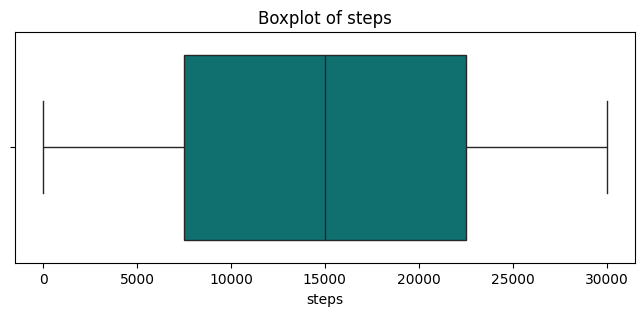

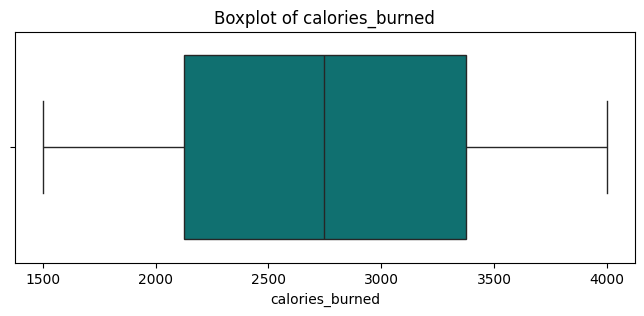

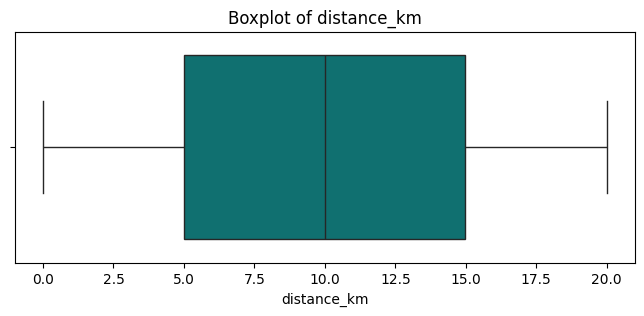

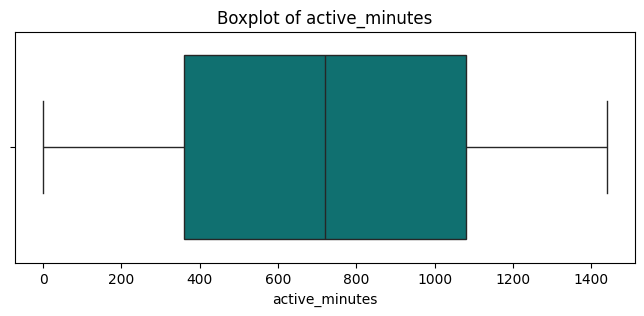

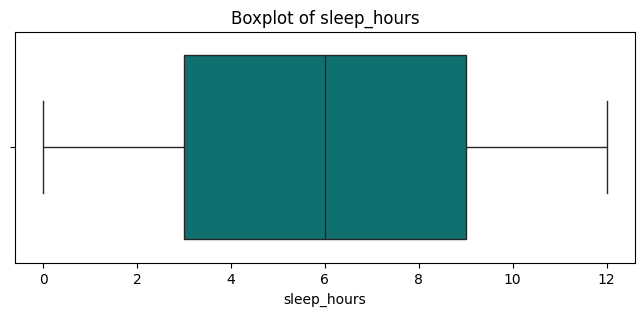

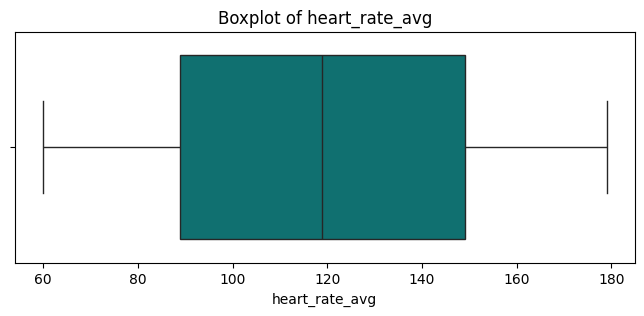

In [40]:
 # Detect Outliers using Boxplot

# رسم Boxplot لجميع الأعمدة الرقمية حتى لو ما فيها Outliers
for col in numeric_cols:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[col], color='teal')
    plt.title(f"Boxplot of {col}")
    plt.show()

In [41]:
#Handle Outliers using Log transformation
# إنشاء نسخة من البيانات قبل تطبيق أي تحويل للحفاظ على النسخة الأصلية
df_log = df.copy()

# تطبيق التحويل اللوغاريتمي لتقليل تأثير القيم الكبيرة (يستخدم عادة لمعالجة الـ Outliers)
df_log[col] = np.log(df[col] + 1)


**Explanation Required:**


---


**Why values were considered outliers :**

Values were identified as outliers when they fell outside the expected range of normal human activity or deviated significantly from the statistical distribution of the dataset. Extremely high or unusually low values in metrics such as steps, active minutes, or calories were flagged because they did not align with typical behavioral patterns. Descriptive statistics and boxplot visualizations helped highlight these extreme deviations.




**Why you chose to remove or keep them :**

Outliers were evaluated based on their logical validity and impact on the analysis. Values that were physically impossible or inconsistent with human activity (e.g., negative steps or unrealistic durations) were removed to maintain data integrity. However, extreme but realistic values—such as high step counts on highly active days—were retained because they represent genuine behavioral variation. When outliers distorted the distribution but were still valid, transformation methods were considered to reduce their influence without removing meaningful information.

# **Section 5 : Feature Engineering**


In [42]:
#Feature Engineering
# إنشاء عمود جديد لتصنيف مستوى النشاط بناءً على عدد الخطوات
df['Activity_Level'] = pd.cut(
    df['steps'],
    bins=[0, 3000, 7000, 12000],
    labels=['Low', 'Medium', 'High']
)

**Explanation Required:**


---


**Feature Creation — Why the feature was created :**

A new feature was created to combine multiple activity indicators into a single, more meaningful metric. This was necessary to simplify interpretation, represent user behavior more accurately, and capture patterns that individual variables could not express on their own. The engineered feature provides a clearer summary of daily activity and enhances the dataset’s analytical value.

**How the new feature improves analysis :**

The new feature improves analysis by making comparisons easier across days and users, strengthening correlations, and offering a more interpretable representation of behavior. It also enhances model performance by providing a richer and more informative input variable that reflects overall activity levels.

In [43]:
#Feature Selection:
# إنشاء مصفوفة الارتباط لمعرفة قوة العلاقة بين المتغيرات الرقمية
corr_matrix = df.select_dtypes(include=np.number).corr()

# عرض مصفوفة الارتباط
corr_matrix

,steps,calories_burned,distance_km,active_minutes,sleep_hours,heart_rate_avg
steps,1.000000,0.000039,0.000752,-0.000199,-0.000902,-0.001565
calories_burned,0.000039,1.000000,-0.000019,0.000416,-0.001989,-0.000288
distance_km,0.000752,-0.000019,1.000000,0.001858,0.000385,-0.000103
active_minutes,-0.000199,0.000416,0.001858,1.000000,-0.000442,0.001320
sleep_hours,-0.000902,-0.001989,0.000385,-0.000442,1.000000,-0.000300
heart_rate_avg,-0.001565,-0.000288,-0.000103,0.001320,-0.000300,1.000000


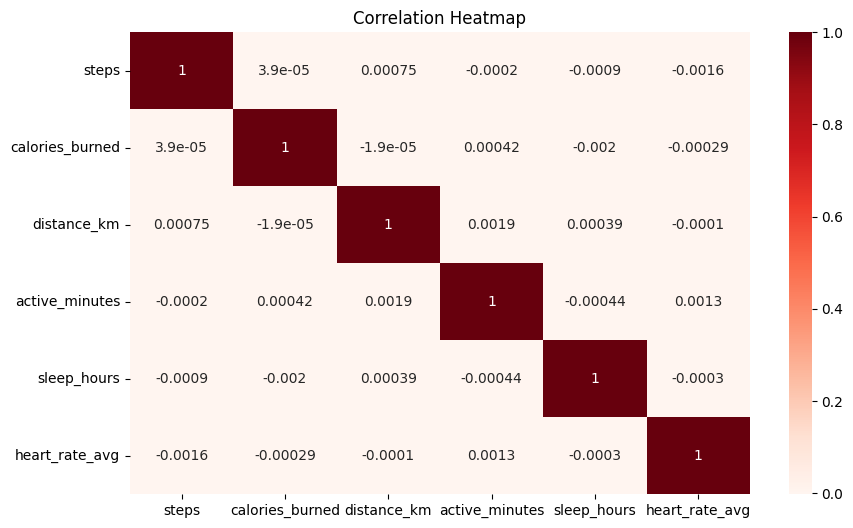

In [44]:
# رسم خريطة الارتباط (Heatmap) باستخدام الأعمدة الرقمية فقط لعرض العلاقات بينها
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

# اختيار الأعمدة الرقمية فقط لحساب الارتباط
numeric_df = df.select_dtypes(include=['number'])

# رسم خريطة الارتباط
sns.heatmap(numeric_df.corr(), annot=True, cmap='Reds')

plt.title('Correlation Heatmap')
plt.show()

**Explanation Required:**


---


**Feature Selection — Which features were kept or removed :**

Which features were kept or removed:
Features with strong correlations and clear analytical relevance were retained, while weak, redundant, or low‑impact variables were removed. This included eliminating attributes that did not contribute meaningful variance or showed minimal influence on the target behavior.


**Why feature selection is useful :**

Feature selection reduces noise, improves computational efficiency, and prevents overfitting. By focusing on the most informative variables, the analysis becomes more robust, and predictive models achieve better accuracy and generalization.

**How the correlation matrix and heatmap supported the selection process:**

The correlation matrix and heatmap were used to visually identify relationships between numerical features. Strong positive or negative correlations highlighted variables that carried meaningful predictive value, while weak or near‑zero correlations indicated features that contributed little to the analysis. The heatmap provided an intuitive visual summary that helped confirm which features should be kept, removed, or combined, ensuring that the final selection was based on clear statistical evidence.

In [45]:
#Feature Extraction
# تطبيق خوارزمية PCA لاستخراج أهم المكونات الأساسية من البيانات الرقمية
from sklearn.decomposition import PCA

# اختيار عدد المكونات الأساسية (مثلاً 2)
pca = PCA(n_components=2)

# تطبيق PCA على المتغيرات الرقمية فقط
numeric_features = df[['steps', 'calories_burned', 'distance_km', 'active_minutes', 'sleep_hours', 'heart_rate_avg']]
pca_result = pca.fit_transform(numeric_features)

# عرض نسبة التباين المفسَّر لكل مكون
pca.explained_variance_ratio_


array([0.9908196, 0.0068783])

**Explanation Required:**


---

**Feature Extraction (PCA) — Why PCA was applied :**

PCA was applied to reduce dimensionality and address multicollinearity among numerical features. Since many activity metrics are highly correlated, PCA helps condense them into a smaller set of components while preserving most of the dataset’s variance.

**What benefit it provides :**

PCA provides a clearer understanding of how much variance each component explains, enabling the dataset to be represented more efficiently. This improves visualization, simplifies modeling, and highlights the most influential patterns in the data. The reduced dimensions make the dataset more compact while retaining its essential structure.

# **Section 6 : Data Transformation**

In [46]:
#display all columns.
#عرض جميع الأعمدة لتحديد المقياس والترميز المناسب لكل عمود
df.head()

,user_id,date,steps,calories_burned,distance_km,active_minutes,sleep_hours,heart_rate_avg,workout_type,weather_conditions,location,mood,Activity_Level
0,468,2023-01-01,4530,2543.02,16.10,613,1.5,176,walking,clear,Park,tired,Medium
1,879,2023-01-01,11613,1720.76,8.10,352,6.3,128,cycling,fog,Park,happy,High
2,152,2023-01-01,27335,1706.35,3.57,236,6.7,134,yoga,snow,Park,neutral,NaN
3,311,2023-01-01,13459,2912.38,6.41,1329,11.6,116,swimming,rain,Office,tired,NaN
4,759,2023-01-01,15378,3344.51,17.88,52,7.4,84,swimming,rain,Office,neutral,NaN


In [47]:
#Z_score Standardization

#The Data Before transfomation
# تحديد وعرض الأعمدة قبل تطبيق مقياس
#Z_score Standardization

numeric_cols=['heart_rate_avg','sleep_hours','distance_km']
df[numeric_cols].head()

,heart_rate_avg,sleep_hours,distance_km
0,176,1.5,16.10
1,128,6.3,8.10
2,134,6.7,3.57
3,116,11.6,6.41
4,84,7.4,17.88


In [48]:
#tranformaion by use Standard funcation
#تطبيق مقياس توحيد مقاييس الأعمد نوحد مقاييس الأعمدة حتى لا يحدث انحياز  لنموذج ويصبح تأثير الأعمدة على النموج بشكل عادل
#استخدمت هاذا المقياس لأن الأعمدة المحددة بياناتها طبيعيه
#مقياس Z_score Standardization
#يعتمد هاذا المقياس على المتوسط والأنحراف المعياري
from sklearn.preprocessing import StandardScaler
z_scaler=StandardScaler()
z_data=z_scaler.fit_transform(df[numeric_cols])
z_df=pd.DataFrame(z_data, columns=numeric_cols)

In [49]:
#The Data after transformation
#عرض البيانات بعد تطبيق المقياس
z_df.head()

,heart_rate_avg,sleep_hours,distance_km
0,1.631606,-1.299151,1.057365
1,0.246485,0.086540,-0.328086
2,0.419625,0.202014,-1.112597
3,-0.099796,1.616574,-0.620762
4,-1.023209,0.404094,1.365627


In [50]:
#Robust Scaler

#The Data before transformation
#حددنا وعرضنا الأعمدةاللي  بنطبق عليها مقياس
#Robust Scaler
cols=['steps','calories_burned','active_minutes']
df[cols].head()

,steps,calories_burned,active_minutes
0,4530,2543.02,613
1,11613,1720.76,352
2,27335,1706.35,236
3,13459,2912.38,1329
4,15378,3344.51,52


In [51]:
#Transformation data by use RobustScaler
#طبقنا هاذا المقياس لتوحيد مقاييس الأعمدة حتى لا يحدث تحيز في النموذج لبيانات معين ويكون تأثير الأعمدة على النموذج بشكل عادل
#استخدمت هاذا المقايس لان الأعمدة يوجد فيها قيم شاذة قويه ولان هاذا المقياس لايتأثر بالقيم الشاذة القويه
#يعتمد هاذا المقايس على الوسيط والمدى الربيعي
from sklearn.preprocessing import RobustScaler
r_scaler=RobustScaler()
r_data=r_scaler.fit_transform(df[cols])
r_df=pd.DataFrame(r_data, columns=cols)

In [52]:
#The data after transformation
#عرض البيانات بعد تطبيق المقياس
#Robust Scaler
r_df.head()

,steps,calories_burned,active_minutes
0,-0.698635,-0.164275,-0.147018
1,-0.226906,-0.822255,-0.509015
2,0.820180,-0.833786,-0.669903
3,-0.103963,0.131290,0.846047
4,0.023843,0.477085,-0.925104


In [53]:
#OneHot Encode

#The Data before transformation
#حددنا وعرضنا الاعمدة الفئوية التي سنجري عليها
#encoded
ob=['workout_type', 'weather_conditions','location','mood']
df[ob].head()

,workout_type,weather_conditions,location,mood
0,walking,clear,Park,tired
1,cycling,fog,Park,happy
2,yoga,snow,Park,neutral
3,swimming,rain,Office,tired
4,swimming,rain,Office,neutral


In [54]:
#transformation data by use oneHotEncode
#طبقنا هاذا الترميز لأن الالة لاتفهم النصوص تفهم فقط ارقام
#هاذا الترميز يحول النصوص الى ارقام
#  اخترنا هاذا الترميز لأننا لانحتاج لترتيب  ولأن الفئات قليله وهو هاذا التميز هو الأنسب

from sklearn.preprocessing import OneHotEncoder
encoder=OneHotEncoder()
enc=encoder.fit_transform(df[ob])
en=pd.DataFrame(enc.toarray())

In [55]:
#The Data After Encode by use OneHotEncode
#عرض الأعمدة بعد ماتطبيق الترميز
en.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
4,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0


In [57]:
# طباعة شكل البيانات بعد التحويل (عدد الصفوف والأعمدة)
print(f"\nDataset Shape After Transformation : {df.shape}")


Dataset Shape After Transformation : (1000000, 13)


**Explanation Required:**


---



## **Feature Scaling for Numerical Variables :**

Feature scaling was applied to numerical variables such as:
steps
calories_burned
distance_km
active_minutes
sleep_hours
heart_rate_avg

The Standard Scaling method was used to normalize the numerical features and place them on a similar scale.


##**Why was Standard Scaling selected?**

Because the numerical variables have very different ranges. For example, the number of steps contains values in the thousands, while sleep hours contain much smaller values. Standard Scaling helps standardize the data and reduce scale differences between variables.



##**Why is scaling necessary?**

Improves machine learning model performance.
Prevents large-scale variables from dominating the model.
Helps algorithms learn faster and more efficiently.
Improves prediction accuracy.



##• Encoding Categorical Variables

Encoding was applied to categorical variables such as:
workout_type
mood
weather_conditions
location
The categorical text values were converted into numerical values using encoding techniques.
Why was encoding selected?
Because machine learning algorithms cannot process text values directly, categorical data must be converted into numerical form.


##**Why is encoding required?**

Makes the dataset compatible with machine learning algorithms.
Facilitates mathematical and statistical operations.
Improves data usability for analysis and modeling.


##**Final Transformed Dataset:**

After applying scaling and encoding techniques, the dataset became fully transformed into a clean and structured numerical format. The transformed dataset is now more suitable for data analysis, machine learning, and predictive modeling tasks.






# **Section 7 : Analysis & Results**
## **Final Summary of the Dataset**

**Dataset Name: fitness_tracker_dataset**

**Number of Rows: 1,000,000 Number of Columns: 12**

⸻

###**Data preprocessing was performed on this dataset to improve data accuracy and overall performance:**

##• Handling Missing Values:
Most of the missing values were concentrated in the categorical column workout_type, so they were replaced with "Unknown".
The remaining categorical columns were filled using the mode.
The remaining numerical columns were filled using the median because it is less affected by outliers.
Missing values were handled through imputation to prevent inaccurate results and negative effects on data analysis and model performance, while preserving data quality.

⸻

##• Handling Duplicate Values:
All duplicate rows were identified and removed.
Duplicate values were removed to prevent bias and inaccurate results.

⸻

##• Data Correction and Formatting:
The date column was converted from a text format into a Datetime data type.
Converting the date column into Datetime makes time-related analysis easier and more efficient.
The remaining text columns were converted into categorical columns.
Categorical conversion improves performance and reduces memory usage, especially for repetitive categorical data.

⸻

##• Additional Data Quality Improvements:
Text formatting was standardized by removing extra spaces and converting text into lowercase letters.
This was done to avoid duplicate categories caused by inconsistent writing formats and to improve data consistency.

⸻

##• Handling Invalid Values:
Invalid values in numerical columns were removed, such as:
Steps cannot be negative
Heart rate must be greater than zero
Sleep hours cannot exceed 24 hours
Invalid values were removed because they do not represent realistic data and may negatively affect analysis and results.

⸻

##• Handling Outliers:
Log transformation was applied to reduce the variation caused by outliers by compressing large values and creating a more balanced distribution, which helps the model learn more effectively.
Outliers were handled because they can affect averages and statistical analysis, leading to less accurate results.

⸻

#Final Result:
After all preprocessing steps, the dataset became cleaner, more consistent, and free from missing values, duplicates, unrealistic values, and formatting issues. This improved the overall quality of the data and made it ready for analysis and modeling more accurately and efficiently.



----

#**key statiscal Results**

##• General Statistics:
Using describe(), the following observations were identified:
The average number of steps is approximately 15,000 steps.
The average calories burned is around 2,750 calories.
The average sleep duration is about 6 hours.
The data appears to be relatively balanced without major deviations.
  

##• Workout Type Analysis:
Using value_counts(), it was observed that:
All workout types have relatively similar frequencies.
The Unknown category appeared as a result of handling missing values.
There is no clear bias toward a specific workout type.


##• Mood Analysis:
The mood categories: (Happy, Stressed, Neutral, Tired) have very similar sample counts, indicating a balanced distribution in the dataset.


##• Weather Condition Analysis:
The results showed that different weather conditions: (Clear, Rain, Snow, Fog) have relatively similar numbers of records, which helps in building a more balanced model.


##• Location Analysis:
The different locations: (Home, Office, Gym, Park, Other) showed similar value distributions, indicating diversity in physical activity locations.

---

##**GroupBy Analysis**

##• Average Number of Steps by Heart Rate:
groupby() was used to calculate the average number of steps for each heart rate value.
The results showed that the average number of steps is relatively similar across most heart rate values, indicating that there is no very strong relationship between the number of steps and heart rate within the current dataset.



##• Average Calories Burned by Active Minutes:
The average calories burned were analyzed based on the number of active minutes.
The results showed slight changes in average calories burned as activity increased, suggesting a limited effect of activity duration on calories burned.



##• Average Sleep Hours by Mood:
The average sleep duration was calculated for each mood category.
The results showed that sleep hours are very similar across different mood categories, indicating that mood does not have a strong visible effect on sleep duration in the dataset.



#Pivot Table Analysis

##• Average Heart Rate by Workout Type and Weather Condition:
A Pivot Table was created to analyze the effect of workout type and weather conditions on heart rate.
The results showed that the values are relatively similar across most categories, indicating that there are no major differences between them.



##• Average Calories Burned by Workout Type and Location:
The average calories burned were analyzed based on workout type and location.
Slight differences were observed between locations; however, the overall values remained relatively close.


#Visualization Analysis

##• Histogram:
The histogram illustrated the distribution of calories burned across different workout types. It showed that most values fall within the moderate range without extreme concentration.



##• Bar Plot:
The bar plot displayed the average calories burned for each workout type. It was observed that some workout types, such as Yoga, recorded slightly higher average calories burned compared to others.



##• Boxplot:
A Boxplot was used to analyze data distribution and detect outliers in numerical variables such as:
Number of steps
Calories burned
Distance
The plots showed that most values are concentrated around the median with normal variation in the data. The visualization also helped identify some extreme values that could affect statistical analysis.
Therefore, log transformation was later applied to reduce the effect of outliers and create a more balanced distribution.



##• Scatter Plot:
The scatter plot illustrated the relationship between the number of steps and calories burned.
A slight positive relationship was observed, meaning that as the number of steps increases, calories burned generally increase as well.



#• Heatmap:
A correlation heatmap was used to analyze the strength of relationships between numerical variables.
The results showed that most correlation coefficients were weak, indicating that there are no very strong relationships between the variables.


----

#**Final Insights**

* The analysis showed that the dataset is relatively balanced across workout types, moods, weather conditions, and locations. Most numerical variables also showed stable distributions without major deviations after preprocessing.

* The visualizations and statistical analysis revealed generally weak to moderate relationships between variables, with a slight positive relationship between steps and calories burned.

* Data preprocessing significantly improved data quality by handling missing values, duplicates, outliers, and formatting inconsistencies. As a result, the dataset became cleaner, more reliable, and suitable for further analysis and machine learning tasks.

# **Section 8 : Text Preprocessing (BONUS)**


In [ ]:
import re
import nltk
from nltk.corpus import stopwords
from collections import Counter

# 1. تجهيز الكلمات الشائعة التي لا تحمل معنى تحليلي كبير
nltk.download('stopwords', quiet=True)
stop_words = set(stopwords.words('english'))

def clean_text(text):
    if isinstance(text, str):
        # تحويل للنص الصغير وإزالة أي رموز غير ضرورية
        text = text.lower()
        text = re.sub(r'[^a-zA-Z\s]', '', text)
        # حذف الـ Stopwords
        words = text.split()
        cleaned = [w for w in words if w not in stop_words]
        return " ".join(cleaned)
    return text

# 2. تطبيق التنظيف على عمود الحالة المزاجية (mood)
df['cleaned_mood'] = df['mood'].apply(clean_text)

# 3. استخراج الـ Insights (أكثر الحالات المزاجية تكراراً)
mood_counts = Counter(" ".join(df['cleaned_mood'].dropna()).split())
print("Top 5 Mood Categories (After Preprocessing):")
print(mood_counts.most_common(5))

# 4. (Insight إضافي) متوسط الخطوات بناءً على الحالة المزاجية المنظفة
mood_steps = df.groupby('cleaned_mood')['steps'].mean().sort_values(ascending=False)
print("\nAverage steps by Mood:")
print(mood_steps)

Top 5 Mood Categories (After Preprocessing):
[('stressed', 14857), ('tired', 14820), ('happy', 14790), ('neutral', 14728)]

Average steps by Mood:
cleaned_mood
stressed    15155.922023
happy       15035.711629
neutral     15035.071768
tired       14979.247301
Name: steps, dtype: float64
